
Linear SVM: C=0.01
Training Accuracy: 0.8725
Testing Accuracy: 0.8333
Support Vectors: 249


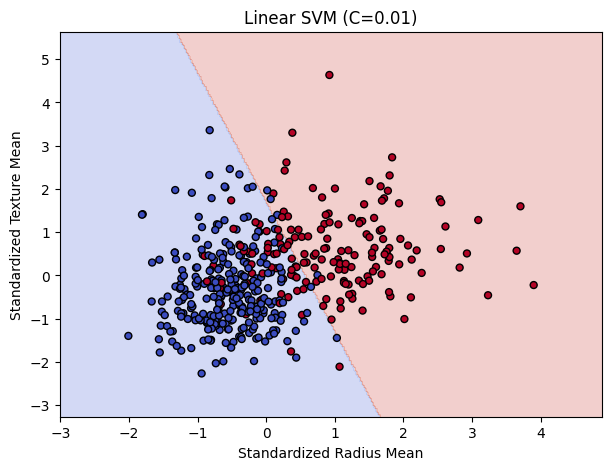


Linear SVM: C=1
Training Accuracy: 0.8923
Testing Accuracy: 0.8684
Support Vectors: 125


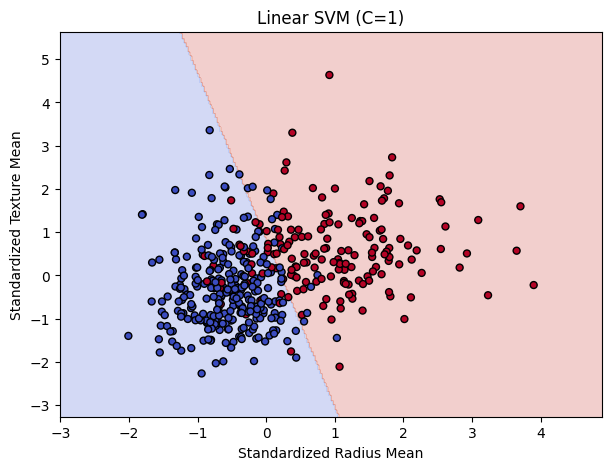


Linear SVM: C=100
Training Accuracy: 0.8945
Testing Accuracy: 0.8772
Support Vectors: 120


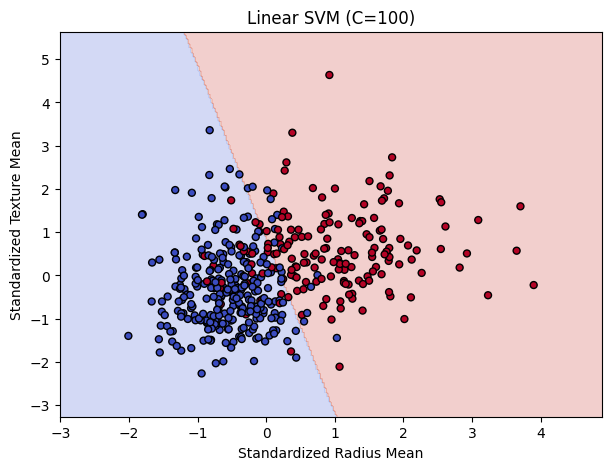


RBF SVM: C=1, Gamma=0.01
Training Accuracy: 0.8835
Testing Accuracy: 0.8596
Support Vectors: 214


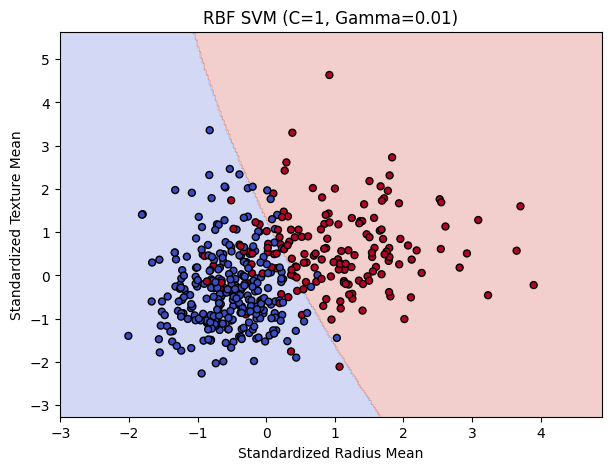


RBF SVM: C=1, Gamma=0.1
Training Accuracy: 0.9077
Testing Accuracy: 0.8947
Support Vectors: 144


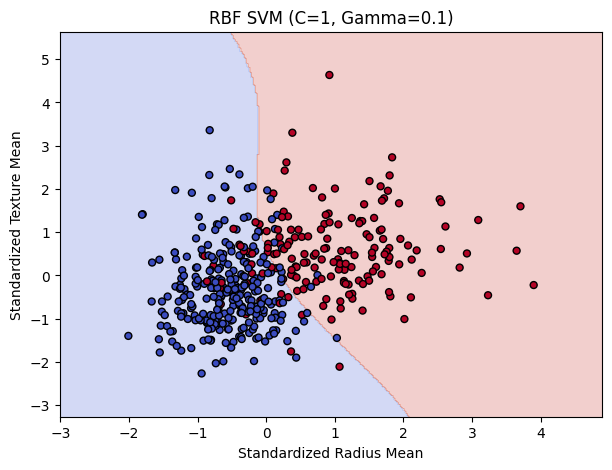


RBF SVM: C=1, Gamma=1
Training Accuracy: 0.9099
Testing Accuracy: 0.9035
Support Vectors: 137


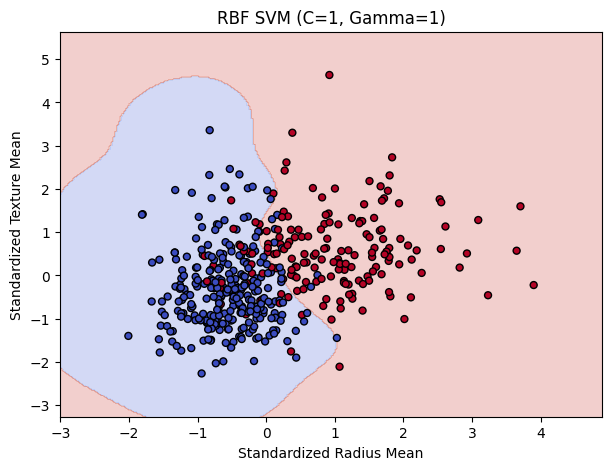


RBF SVM: C=1, Gamma=10
Training Accuracy: 0.9165
Testing Accuracy: 0.9211
Support Vectors: 252


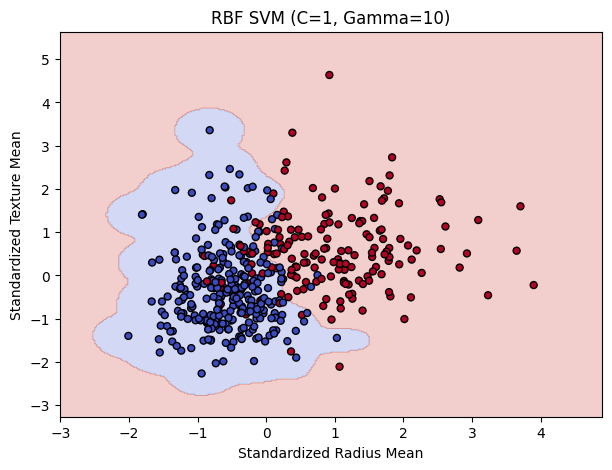


Comparison Table:
Kernel      C Gamma  Train Accuracy  Test Accuracy  Number of Support Vectors
Linear   0.01     -        0.872527       0.833333                        249
Linear   1.00     -        0.892308       0.868421                        125
Linear 100.00     -        0.894505       0.877193                        120
   RBF   1.00  0.01        0.883516       0.859649                        214
   RBF   1.00   0.1        0.907692       0.894737                        144
   RBF   1.00     1        0.909890       0.903509                        137
   RBF   1.00    10        0.916484       0.921053                        252

Classification Report for RBF SVM (C=1, Gamma=0.1):
              precision    recall  f1-score   support

      Benign       0.87      0.99      0.92        72
   Malignant       0.97      0.74      0.84        42

    accuracy                           0.89       114
   macro avg       0.92      0.86      0.88       114
weighted avg       0.90      0.8

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv('/content/breast-cancer-wisconsin-dataset.csv')

df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df = df.dropna()

X = df[['radius_mean', 'texture_mean']].values
y = df['diagnosis'].map({'B': 0, 'M': 1}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm',
                edgecolors='black', s=25)
    plt.xlabel('Standardized Radius Mean')
    plt.ylabel('Standardized Texture Mean')
    plt.title(title)
    plt.show()

results = []

for C in [0.01, 1, 100]:
    model = SVC(kernel='linear', C=C)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    results.append([
        'Linear', C, '-', train_acc, test_acc,
        model.n_support_.sum()
    ])

    print(f'\nLinear SVM: C={C}')
    print(f'Training Accuracy: {train_acc:.4f}')
    print(f'Testing Accuracy: {test_acc:.4f}')
    print(f'Support Vectors: {model.n_support_.sum()}')

    plot_boundary(
        model, X_train, y_train,
        f'Linear SVM (C={C})'
    )

for gamma in [0.01, 0.1, 1, 10]:
    model = SVC(kernel='rbf', C=1, gamma=gamma)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    results.append([
        'RBF', 1, gamma, train_acc, test_acc,
        model.n_support_.sum()
    ])

    print(f'\nRBF SVM: C=1, Gamma={gamma}')
    print(f'Training Accuracy: {train_acc:.4f}')
    print(f'Testing Accuracy: {test_acc:.4f}')
    print(f'Support Vectors: {model.n_support_.sum()}')

    plot_boundary(
        model, X_train, y_train,
        f'RBF SVM (C=1, Gamma={gamma})'
    )

results_df = pd.DataFrame(
    results,
    columns=[
        'Kernel', 'C', 'Gamma',
        'Train Accuracy', 'Test Accuracy',
        'Number of Support Vectors'
    ]
)

print('\nComparison Table:')
print(results_df.to_string(index=False))

best_model = SVC(kernel='rbf', C=1, gamma=0.1)
best_model.fit(X_train, y_train)

print('\nClassification Report for RBF SVM (C=1, Gamma=0.1):')
print(classification_report(
    y_test, best_model.predict(X_test),
    target_names=['Benign', 'Malignant']
))
